In [84]:
import pandas as pd
import numpy as np
import os
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [85]:

stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/东非裂谷数据/SE_ps_new_2.csv')

# EQT

In [86]:

phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/EastAfican_Predict/EastAfican_Eqtransformer/picks.csv')
# phasenet=phasenet.loc[:100000,:]

# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]
# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')

# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,20100214_044850_ZP_KGMA_BH,2880.0,4000.0,2849,4002.0,31.0,-2.0
1,20130603_032443_AF_NBI_BH,2440.0,3280.0,2426,3290.0,14.0,-10.0
2,20091108_171404_ZP_TUND_BH,1560.0,1800.0,1579,1800.0,-19.0,0.0
3,20140924_193815_ZV_SUMA_BH,3250.0,4400.0,3275,4401.0,-25.0,-1.0
4,20101120_001141_ZP_GABZ_BH,2240.0,3080.0,2268,3080.0,-28.0,0.0
...,...,...,...,...,...,...,...
2258,20170403_183810_NR_NE211_BH,1480.0,2240.0,1617,2338.0,-137.0,-98.0
2259,20130722_065045_XJ_PR33_BH,3450.0,4650.0,3466,4641.0,-16.0,9.0
2260,20091224_133901_ZP_NJOM_BH,1680.0,2280.0,1695,2273.0,-15.0,7.0
2261,20120513_000923_XV_SENA_BH,2480.0,3360.0,2459,3382.0,21.0,-22.0


In [87]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > TP_threshold_FN, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > TP_threshold_FN, 1, 0)

# #FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result_eqt.loc[:, 'p_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)
# result_eqt.loc[:, 's_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count = 3580-result_eqt['p_TP'].sum() - result_eqt['p_FN'].sum()
s_FP_count = 3580 -result_eqt['s_TP'].sum() - result_eqt['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(stead)*0.2 - len(phasenet['p_idx'])+phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(stead)*0.2 - len(phasenet['s_idx'])+phasenet['s_idx'].isna().sum()
#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100 
s_TP_mae = s_TP_mae / 100 

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100
s_TP_std = result_eqt['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_moe = pd.DataFrame({
    'Moe': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']] = (
    result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 2050
P-FP: 1317
P-FN: 213
P-Precision: 0.6088506088506088
P-Recall: 0.9058771542200619
P-F1 Score: 0.7282415630550622
P-MAE: 0.14916124942536585
P-STD: 0.177763079040158
S-TP: 1684
S-FP: 1438
S-FN: 458
S-Precision: 0.5393978219090326
S-Recall: 0.7861811391223156
S-F1 Score: 0.6398176291793313
S-MAE: 0.16720382788301663
S-STD: 0.16989189447783365


/tmp/ipykernel_6699/2528521182.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_6699/2528521182.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_6699/2528521182.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexe

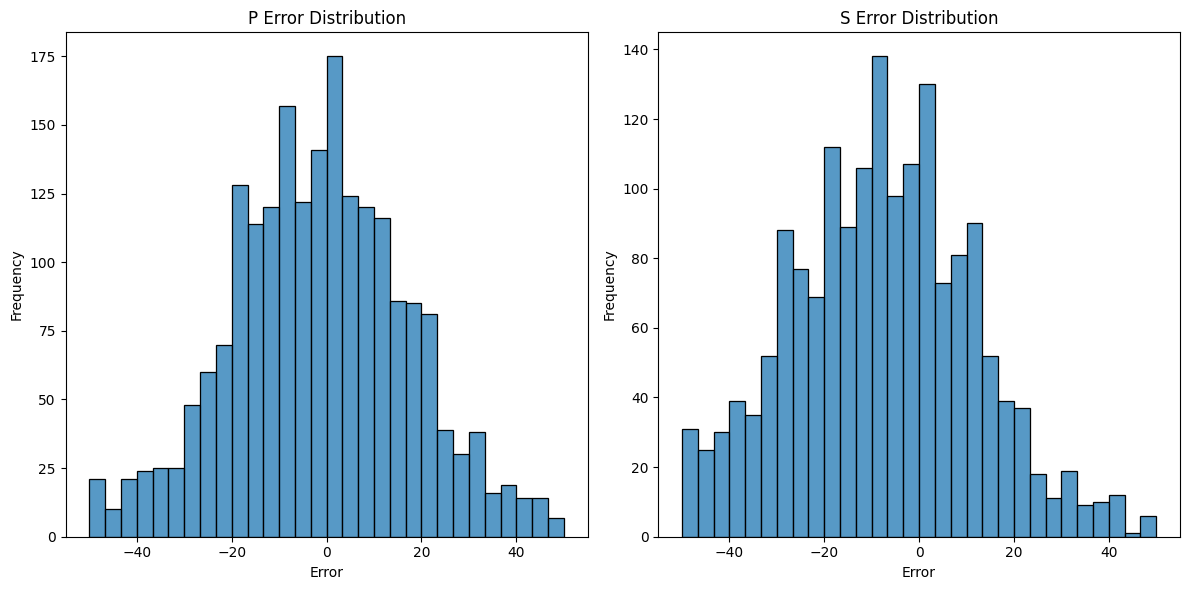

In [88]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# MOE

In [89]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/EastAfican_Predict/EastAfican_Moe/picks.csv')

# phasenet=phasenet.loc[:130000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [90]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,20070811_172603_IU_KMBO_BH,2560.0,3520.0,1836,2532.0,724.0,988.0
1,20130722_065045_XJ_LN15_BH,3150.0,4450.0,1797,2552.0,1353.0,1898.0
2,20170704_113705_NR_NE201_BH,1360.0,1880.0,1944,2721.0,-584.0,-841.0
3,20100112_231434_MW_KARM_BH,1860.0,2860.0,2579,4283.0,-719.0,-1423.0
4,20090810_225448_ZP_CHIM_BH,2400.0,3280.0,1662,2437.0,738.0,843.0
...,...,...,...,...,...,...,...
2599,20091201_042726_ZP_NJOM_BH,2000.0,2520.0,1433,1840.0,567.0,680.0
2600,20171009_051006_AF_MOPA_BH,1160.0,1560.0,1669,2225.0,-509.0,-665.0
2601,20141121_095756_XJ_NG56_BH,2900.0,3900.0,1674,2239.0,1226.0,1661.0
2602,20140826_090749_YQ_MBAM_BH,2900.0,3700.0,1666,2123.0,1234.0,1577.0


In [91]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 500
TP_threshold_S = 500
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_P, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['p_error']) > TP_threshold_P, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_S, 1, 0)

# #FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
# result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算FP的数量
#计算FP的数量
p_FP_count = 3580-result_moe['p_TP'].sum() - result_moe['p_FN'].sum()
s_FP_count = 3580 -result_moe['s_TP'].sum() - result_moe['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(stead)*0.2 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(stead)*0.2 - len(phasenet['s_idx'])-phasenet['s_idx'].isna().sum()
#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum() + phasenet['p_idx'].isna().sum()
s_FN= result_moe['s_FN'].sum() + phasenet['s_idx'].isna().sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_eqt = pd.DataFrame({
    'EQT': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']] = (
    result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 244
P-FP: 976
P-FN: 2360
P-Precision: 0.2
P-Recall: 0.09370199692780339
P-F1 Score: 0.12761506276150628
P-MAE: 4.096884087520492
P-STD: 1.2777499784102373
S-TP: 98
S-FP: 1051
S-FN: 2506
S-Precision: 0.08529155787641428
S-Recall: 0.03763440860215054
S-F1 Score: 0.052224886757260856
S-MAE: 4.169181248571428
S-STD: 0.8336393772961482


/tmp/ipykernel_6699/2219470805.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_6699/2219470805.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_6699/2219470805.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer]

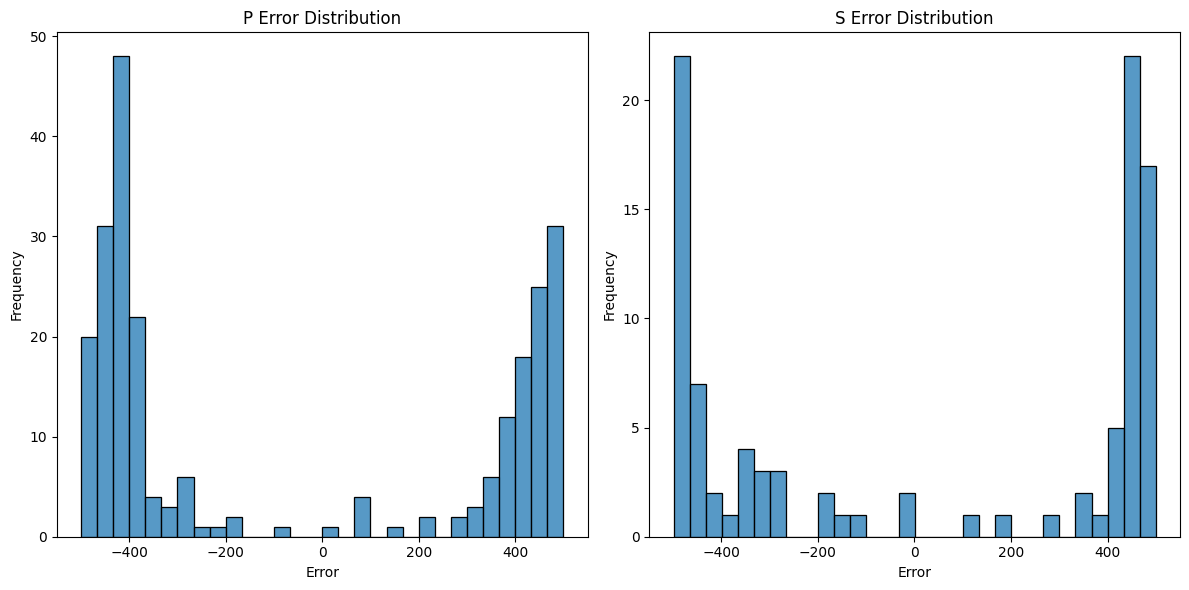

In [92]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# PhaseNet

In [93]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/EastAfican_Predict/EastAfican_PhaseNet/picks.csv')
# phasenet=phasenet.loc[:10000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [94]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,20100213_152048_YI_LUGH_HH,3600.0,3900.0,3625,3931.0,-25.0,-31.0
1,20140826_090749_YQ_ITUM_BH,3050.0,3900.0,3028,3884.0,22.0,16.0
2,20070818_074401_IU_KMBO_HN,5040.0,6880.0,5036,5279.0,4.0,1601.0
3,20140128_080759_XJ_LN46_BH,3000.0,4200.0,3015,4193.0,-15.0,7.0
4,20140910_010451_ZV_KIPA_BH,2300.0,2750.0,2314,2733.0,-14.0,17.0
...,...,...,...,...,...,...,...
2665,20091125_211433_ZP_SONG_BH,2520.0,3560.0,2552,3563.0,-32.0,-3.0
2666,20110706_103745_6H_SUSS_BH,3100.0,4150.0,3081,4174.0,19.0,-24.0
2667,20210206_021853_BX_PHDHD_BH,2240.0,2920.0,2252,2916.0,-12.0,4.0
2668,20170404_194156_NR_NE212_BH,1020.0,1260.0,1022,1267.0,-2.0,-7.0


In [95]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 50
TP_threshold_S = 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_S, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result_phasenet.loc[:, 'p_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)
# result_phasenet.loc[:, 's_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count =3580- result_phasenet['p_TP'].sum() -result_phasenet['p_FN'].sum()
s_FP_count =3580- result_phasenet['s_TP'].sum() -result_phasenet['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(phasenet)*0.2 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(phasenet)*0.2 - len(phasenet['s_idx'])-phasenet['s_idx'].isna().sum()

#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()
s_FN= result_phasenet['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

#将结果做成一个表格
result_table_phasenet = pd.DataFrame({
    'PhaseNet': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']] = (
    result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 2176
P-FP: 910
P-FN: 494
P-Precision: 0.7051198963058976
P-Recall: 0.8149812734082397
P-F1 Score: 0.7560806115357886
P-MAE: 0.16030813194301474
P-STD: 0.17272019926906024
S-TP: 1805
S-FP: 1020
S-FN: 755
S-Precision: 0.6389380530973451
S-Recall: 0.705078125
S-F1 Score: 0.670380687093779
S-MAE: 0.18581224348199446
S-STD: 0.16494545521692947


/tmp/ipykernel_6699/2989024496.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_6699/2989024496.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_6699/2989024496.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_

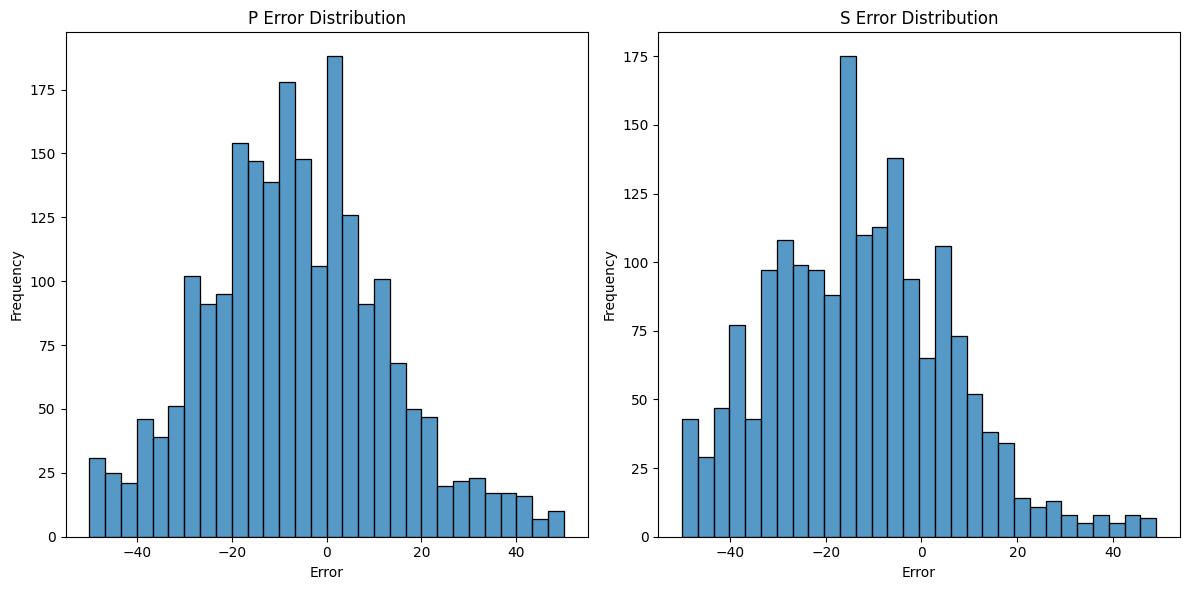

In [96]:

import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
data=result_phasenet[result_phasenet['p_TP'] == 1]['p_error']

sns.histplot(result_phasenet[result_phasenet['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_phasenet[result_phasenet['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# Results

In [97]:
import pandas as pd

# 1) 以 EQT 表举例
df_eqt = result_table_eqt.set_index('EQT')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('EQT', col) for col in df_eqt.columns])

# 2) Moe 表同理
df_moe = result_table_moe.set_index('Moe')
df_moe.columns = pd.MultiIndex.from_tuples([('Moe', col) for col in df_moe.columns])

# 3) PhaseNet 表
df_phasenet = result_table_phasenet.set_index('PhaseNet')
df_phasenet.columns = pd.MultiIndex.from_tuples([('PhaseNet', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_moe,df_eqt, df_phasenet], axis=1)

print('-------------------------------------stead--------------------------------------------')
df_multi


-------------------------------------stead--------------------------------------------


Moe                       EQT                  PhaseNet  \
                     P            S            P            S            P   
TP         2050.000000  1684.000000   244.000000    98.000000  2176.000000   
FP         1317.000000  1438.000000   976.000000  1051.000000   910.000000   
FN          213.000000   458.000000  2360.000000  2506.000000   494.000000   
Precision     0.608851     0.539398     0.200000     0.085292     0.705120   
Recall        0.905877     0.786181     0.093702     0.037634     0.814981   
F1 Score      0.728242     0.639818     0.127615     0.052225     0.756081   
MAE           0.149161     0.167204     4.096884     4.169181     0.160308   
STD           0.177763     0.169892     1.277750     0.833639     0.172720   

                        
                     S  
TP         1805.000000  
FP         1020.000000  
FN          755.000000  
Precision     0.638938  
Recall        0.705078  
F1 Score      0.670381  
MAE           0.185812  
STD           0.164945

# figure

In [98]:
# import h5py
# import pandas as pd
# import matplotlib.pyplot as plt
# import os

# # 输入路径
# hd = '/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
# output_dir = '/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/Figure/output_waveforms_STEAD/'
# os.makedirs(output_dir, exist_ok=True)

# # ===== 读取数据并求交集 =====
# # 筛选 P/S 都为 TP 的 trace_name
# eqt_tp = result_eqt[(result_eqt['p_TP'] == 1) & (result_eqt['s_TP'] == 1)]['trace_name']
# moe_tp = result_moe[(result_moe['p_TP'] == 1) & (result_moe['s_TP'] == 1)]['trace_name']
# phasenet_tp = result_phasenet[(result_phasenet['p_TP'] == 1) & (result_phasenet['s_TP'] == 1)]['trace_name']
# common_traces = set(eqt_tp) & set(moe_tp) & set(phasenet_tp)

# # 筛选出三组数据对应的行
# df_eqt = result_eqt[result_eqt['trace_name'].isin(common_traces)].copy()
# df_moe = result_moe[result_moe['trace_name'].isin(common_traces)].copy()
# df_phasenet = result_phasenet[result_phasenet['trace_name'].isin(common_traces)].copy()

# # 设置索引，便于 trace_name 访问
# moe_dict = df_moe.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# phasenet_dict = df_phasenet.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# df_eqt=df_eqt.sample(n=100,random_state=42).copy()
# # ===== 读取波形并绘图 =====
# with h5py.File(hd, 'r') as f:
#     for i, row in df_eqt.iterrows():
#         if row['trace_category'] == 'noise':
#             continue

#         trace_name = row['trace_name']
#         try:
#             data = f['data'][trace_name][()]  # shape: (3, 6000)
#         except KeyError:
#             print(f"[WARN] Missing trace: {trace_name}")
#             continue

#         z, n, e = data[:,0], data[:,1], data[:,2]

#         p_arrival = row['p_arrival_sample']
#         s_arrival = row['s_arrival_sample']
#         p_eqt = row['p_idx']
#         s_eqt = row['s_idx']
#         p_moe = moe_dict[trace_name]['p_idx']
#         s_moe = moe_dict[trace_name]['s_idx']
#         p_phase = phasenet_dict[trace_name]['p_idx']
#         s_phase = phasenet_dict[trace_name]['s_idx']

#         fig, axs = plt.subplots(5, 1, figsize=(12, 10), sharex=False)
#         components = [z, n, e]
#         labels = ['Z', 'N', 'E']

#         for idx, (ax, comp, label) in enumerate(zip(axs[:3], components, labels)):
#             ax.plot(comp, label=f'{label} component')

#             # 到时标注
#             ax.axvline(p_arrival, color='green', linestyle='--', label='P Arrival')
#             ax.axvline(s_arrival, color='blue', linestyle='--', label='S Arrival')
#             ax.axvline(p_eqt, color='red', linestyle=':', label='EQT P')
#             ax.axvline(s_eqt, color='purple', linestyle=':', label='EQT S')
#             ax.axvline(p_moe, color='orange', linestyle=':', label='Moe P')
#             ax.axvline(s_moe, color='brown', linestyle=':', label='Moe S')
#             ax.axvline(p_phase, color='pink', linestyle='--', label='PhaseNet P')
#             ax.axvline(s_phase, color='cyan', linestyle='--', label='PhaseNet S')

#             ax.set_ylabel(label)
#             ax.legend(loc='upper right', fontsize=8)

#         # 第四图：P 波放大图（Z）
#         start_p = max(0, int(min(p_arrival, p_eqt, p_moe, p_phase) - 50))
#         end_p = min(6000, int(max(p_arrival, p_eqt, p_moe, p_phase) + 50))
#         axs[3].plot(z[start_p:end_p], label='Z (P Zoom)')
#         axs[3].axvline(p_arrival - start_p, color='black', linestyle='--', label='P Arrival')
#         axs[3].axvline(p_eqt - start_p, color='green', linestyle=':', label='EQT P')
#         axs[3].axvline(p_moe - start_p, color='red', linestyle=':', label='Moe P')
#         axs[3].axvline(p_phase - start_p, color='orange', linestyle='--', label='PhaseNet P')
#         axs[3].legend(loc='upper right', fontsize=8)
#         axs[3].set_ylabel('Z (P Zoom)')

#         # 第五图：S 波放大图（Z）
#         start_s = max(0, int(min(s_arrival, s_eqt, s_moe, s_phase) - 50))
#         end_s = min(6000, int(max(s_arrival, s_eqt, s_moe, s_phase) + 50))
#         axs[4].plot(z[start_s:end_s], label='Z (S Zoom)')
#         axs[4].axvline(s_arrival - start_s, color='black', linestyle='--', label='S Arrival')
#         axs[4].axvline(s_eqt - start_s, color='green', linestyle=':', label='EQT S')
#         axs[4].axvline(s_moe - start_s, color='red', linestyle=':', label='Moe S')
#         axs[4].axvline(s_phase - start_s, color='orange', linestyle='--', label='PhaseNet S')
#         axs[4].legend(loc='upper right', fontsize=8)
#         axs[4].set_ylabel('Z (S Zoom)')

#         # 保存图像
#         fig.suptitle(f'Trace: {trace_name}', fontsize=14)
#         plt.tight_layout(rect=[0, 0.03, 1, 0.95])
#         out_path = os.path.join(output_dir, f'{trace_name}.png')
#         plt.savefig(out_path)
#         plt.close(fig)


In [99]:
import h5py
import pandas as pd
input_csv=r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/东非裂谷数据/SE_ps_new_2.csv'
hdf5_path=r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/东非裂谷数据/ES.hdf5'
csv=pd.read_csv(input_csv)
f=h5py.File(hdf5_path,'r')
ff=f['data']
len(ff.keys())
trace_name=ff.keys()

comm=set(trace_name) & set(csv['trace_name'].tolist())

len(comm)

3567